In [1]:
from importlib import reload
import plotting_utils as pu

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

cell_types = ["Exc", "Pvalb", "Sst", "Vip", "Htr3a"]
colors = [
    "tab:red",
    "tab:blue",
    "tab:green",
    "tab:purple",
    "tab:purple",
]
layers = ["L1", "L2/3", "L4", "L5", "L6"]

cell_labels = {
    "Exc": "Exc",
    "Pvalb": "Pvalb",
    "Sst": "Sst",
    "Vip": "Vip",
    "Htr3a": "L1 Inh",
}

## Fig 4 suppl: firing rates distribution

In [2]:
net_name = "core"  # change to "core_<variant>" for a model variant
Perturb_dict = {
    "no perturb": "_checkpoint",
    "silencing L1": "_opto_layer_silencing_L1_-2000_checkpoint",
    "silencing L2/3": "_opto_layer_silencing_L23_-2000_checkpoint",
    "silencing L4": "_opto_layer_silencing_L4_-2000_checkpoint",
    "silencing L5": "_opto_layer_silencing_L5_-2000_checkpoint",
    "silencing L6": "_opto_layer_silencing_L6_-2000_checkpoint",
    "isolated L1": "_opto_layer_silencing_L23_L4_L5_L6_-2000_checkpoint",
    "isolated L2/3": "_opto_layer_silencing_L1_L4_L5_L6_-2000_checkpoint",
    "isolated L4": "_opto_layer_silencing_L1_L23_L5_L6_-2000_checkpoint",
    "isolated L5": "_opto_layer_silencing_L1_L23_L4_L6_-2000_checkpoint",
    "isolated L6": "_opto_layer_silencing_L1_L23_L4_L5_-2000_checkpoint",
    "silencing 100% i4Vip": "_onlyL4_-2000_silencing_i4Vip_100perc_checkpoint",
    "silencing 83.33% i4Vip": "_onlyL4_-2000_silencing_i4Vip_83.33perc_checkpoint",
    "silencing 75.0% i4Vip": "_onlyL4_-2000_silencing_i4Vip_75.0perc_checkpoint",
    "silencing 62.5% i4Vip": "_onlyL4_-2000_silencing_i4Vip_62.5perc_checkpoint",
    "silencing 50.0% i4Vip": "_onlyL4_-2000_silencing_i4Vip_50perc_checkpoint",
    "silencing 25.0% i4Vip": "_onlyL4_-2000_silencing_i4Vip_25perc_checkpoint",
    "silencing 10.0% i4Vip": "_onlyL4_-2000_silencing_i4Vip_10perc_checkpoint",
    "silencing 100% i4Pvalb": "_onlyL4_-2000_silencing_i4Pvalb_100perc_checkpoint",
    "silencing 83.33% i4Pvalb": "_onlyL4_-2000_silencing_i4Pvalb_83.33perc_checkpoint",
    "silencing 75.0% i4Pvalb": "_onlyL4_-2000_silencing_i4Pvalb_75.0perc_checkpoint",
    "silencing 62.5% i4Pvalb": "_onlyL4_-2000_silencing_i4Pvalb_62.5perc_checkpoint",
    "silencing 50.0% i4Pvalb": "_onlyL4_-2000_silencing_i4Pvalb_50perc_checkpoint",
    "silencing 25.0% i4Pvalb": "_onlyL4_-2000_silencing_i4Pvalb_25perc_checkpoint",
    "silencing 10.0% i4Pvalb": "_onlyL4_-2000_silencing_i4Pvalb_10perc_checkpoint",
    "silencing 100% i4Sst": "_onlyL4_-2000_silencing_i4Sst_100perc_checkpoint",
    "silencing 83.33% i4Sst": "_onlyL4_-2000_silencing_i4Sst_83.33perc_checkpoint",
    "silencing 75.0% i4Sst": "_onlyL4_-2000_silencing_i4Sst_75.0perc_checkpoint",
    "silencing 62.5% i4Sst": "_onlyL4_-2000_silencing_i4Sst_62.5perc_checkpoint",
    "silencing 50.0% i4Sst": "_onlyL4_-2000_silencing_i4Sst_50perc_checkpoint",
    "silencing 25.0% i4Sst": "_onlyL4_-2000_silencing_i4Sst_25perc_checkpoint",
    "silencing 10.0% i4Sst": "_onlyL4_-2000_silencing_i4Sst_10perc_checkpoint",
}

config_files_path = f"{net_name}/configs"


def get_condition_color(condition):
    if condition == "no perturb":
        return "white"
    elif "Vip" in condition:
        return "tab:purple"
    elif "Pvalb" in condition:
        return "tab:blue"
    elif "Sst" in condition:
        return "tab:green"
    return "gray"


perturb_palette = {cond: get_condition_color(cond) for cond in Perturb_dict}

In [3]:
v1df_all = pd.DataFrame()
for condition, file_info in Perturb_dict.items():
    print(condition)
    file_name = (
        config_files_path
        + f"/8dir_10trials{file_info}"
        + "/config_0.json"
    )
    v1df, spike_df = pu.data_organize(
        file_name, t_min=500, t_max=3000, radius=pu.settings["core"]["radius"]
    )
    v1df["condition"] = condition
    v1df_all = pd.concat([v1df_all, v1df])

v1df_all["cell_type"] = v1df_all["cell_type"].map(cell_labels)

v1df_all["cell_layer"] = v1df_all.apply(
    lambda row: row["layer"] + " " + row["cell_type"] if row["layer"] != "L1" else "L1 Inh", axis=1
)

layer_cell = v1df_all["cell_layer"].unique().tolist()

no perturb
inferring network from core


silencing L1
inferring network from core


silencing L2/3
inferring network from core


silencing L4
inferring network from core


silencing L5
inferring network from core


silencing L6
inferring network from core


... (22 outputs left out)

silencing 62.5% i4Sst
inferring network from core


silencing 50.0% i4Sst
inferring network from core


silencing 25.0% i4Sst
inferring network from core


silencing 10.0% i4Sst
inferring network from core


/tmp/ipykernel_3701444/2072781647.py:88: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=xlabel_rotation, ha=ha)


/tmp/ipykernel_3701444/2072781647.py:88: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=xlabel_rotation, ha=ha)


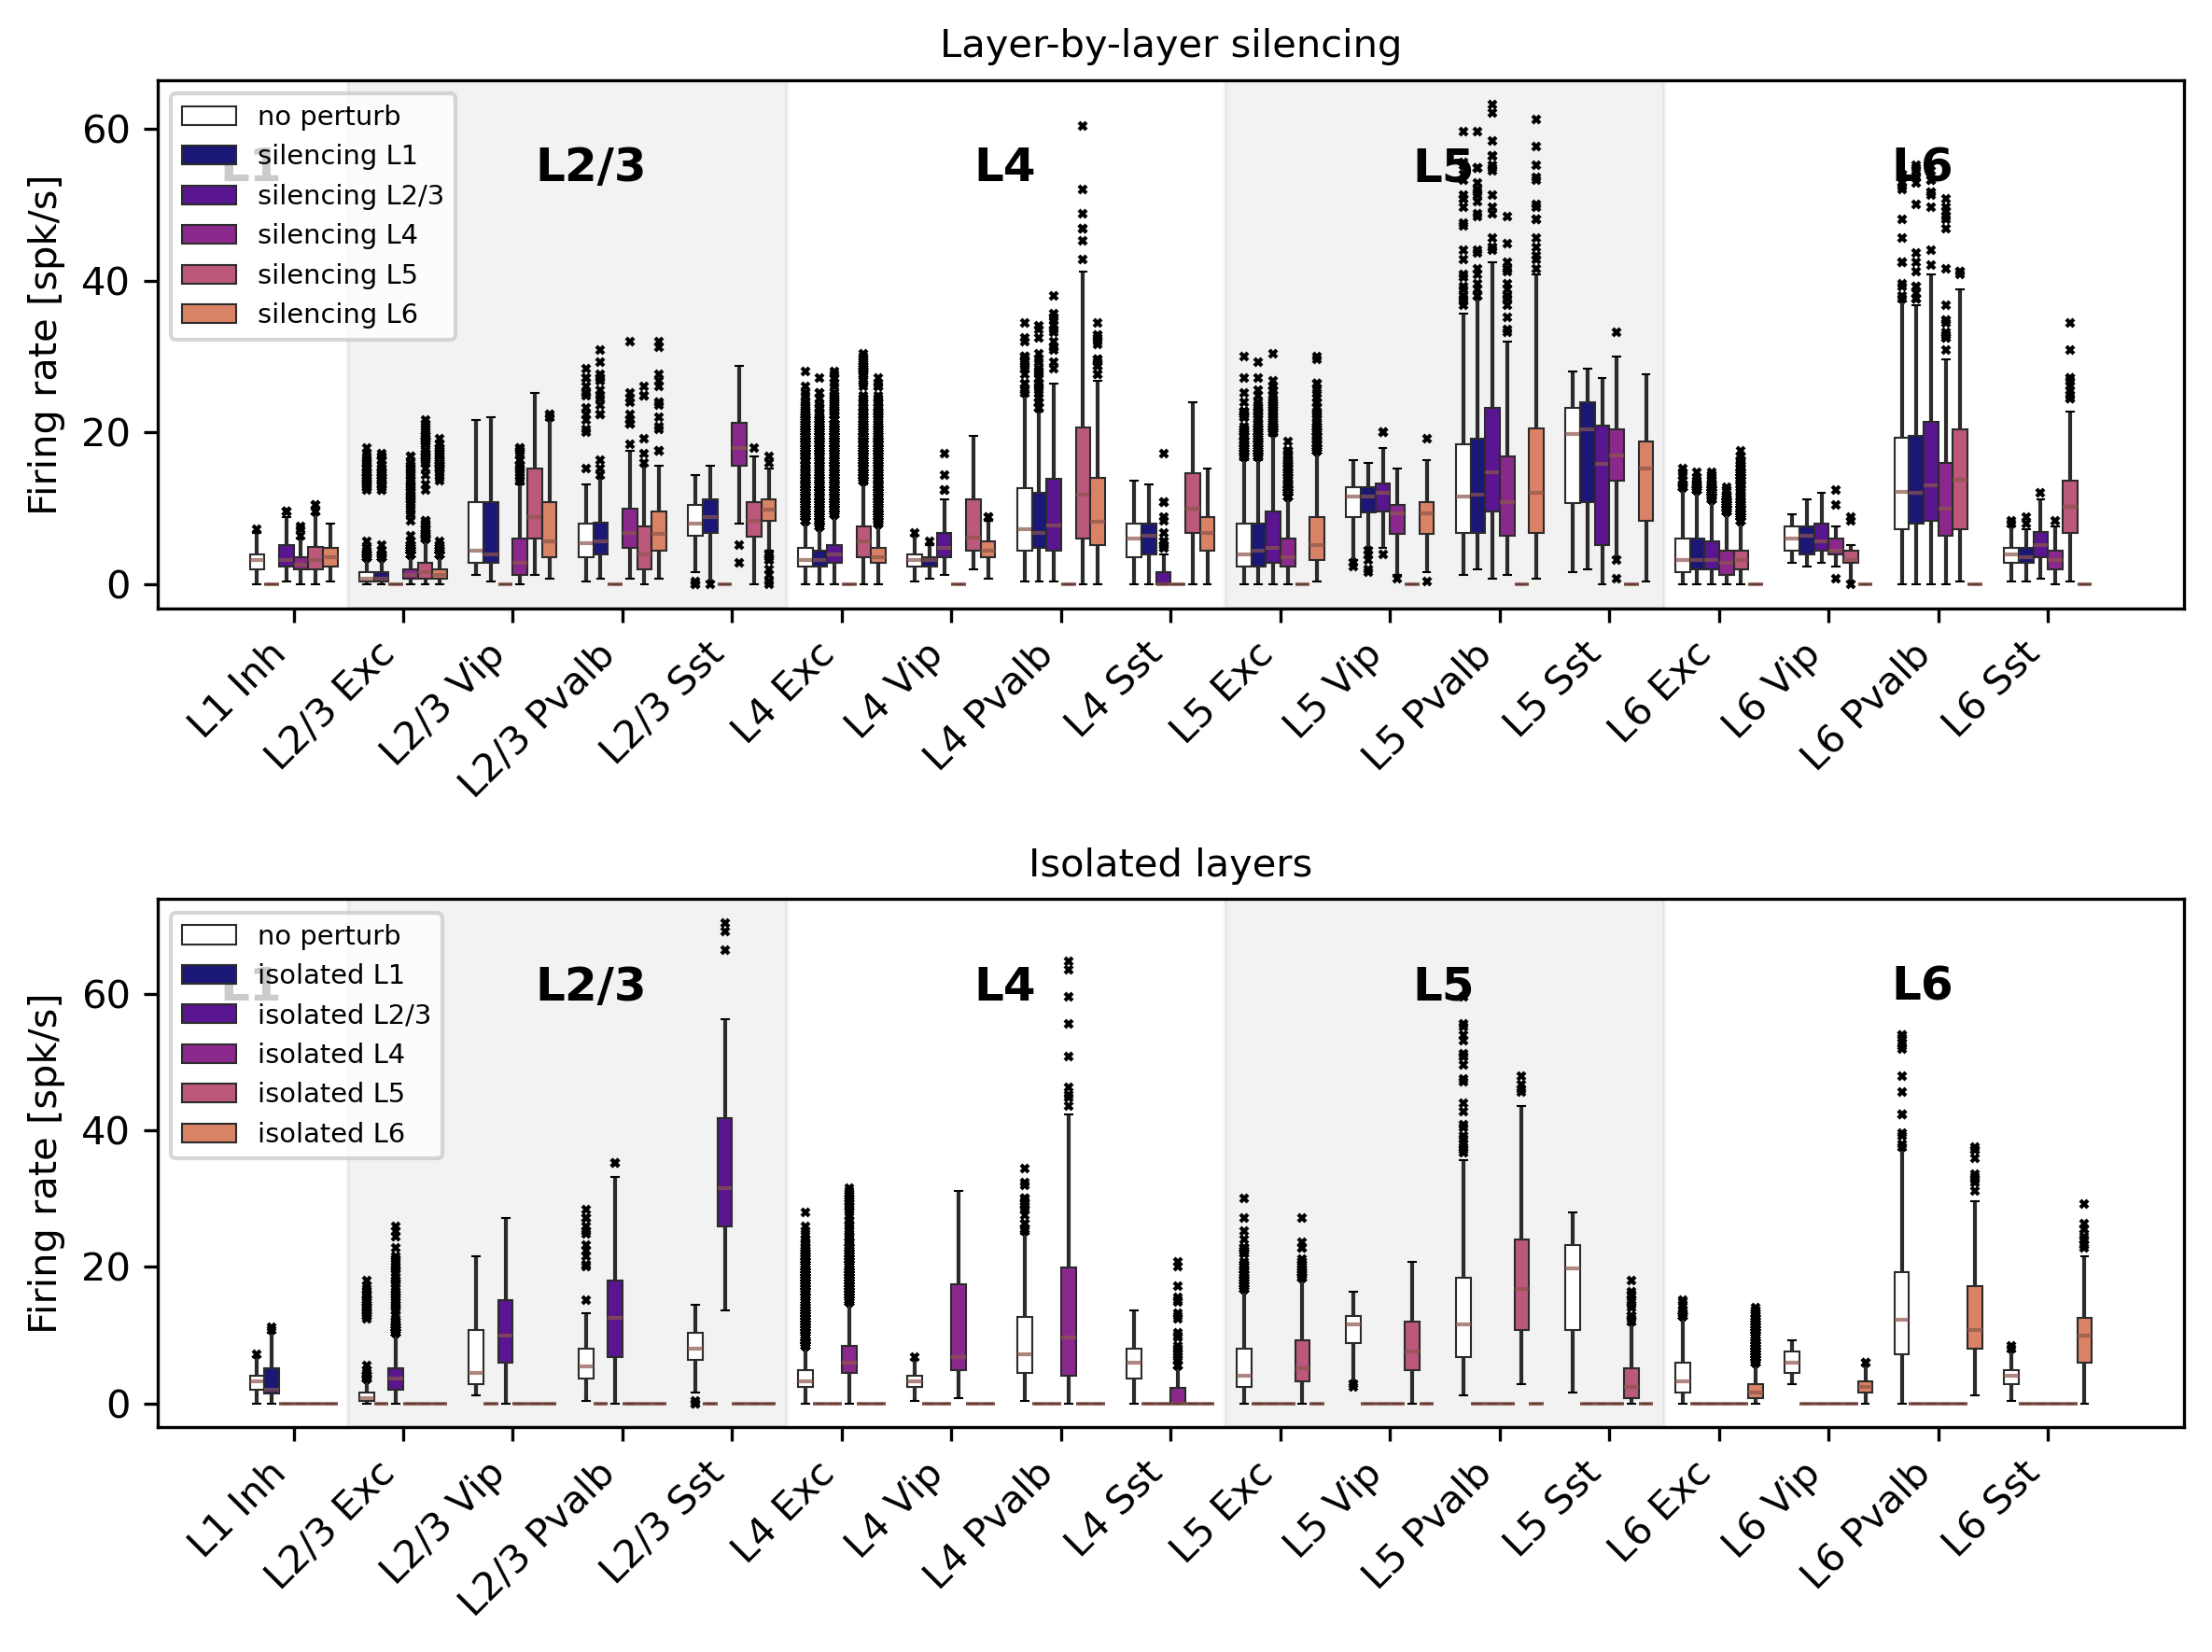

In [4]:
subplot_conditions = [
    ["no perturb", "silencing L1", "silencing L2/3", "silencing L4", "silencing L5", "silencing L6"],
    ["no perturb", "isolated L1", "isolated L2/3", "isolated L4", "isolated L5", "isolated L6"],
    ["no perturb", "silencing 10.0% i4Pvalb", "silencing 25.0% i4Pvalb", "silencing 50.0% i4Pvalb", "silencing 62.5% i4Pvalb", "silencing 75.0% i4Pvalb", "silencing 83.33% i4Pvalb", "silencing 100% i4Pvalb"],
    ["no perturb", "silencing 10.0% i4Sst", "silencing 25.0% i4Sst", "silencing 50.0% i4Sst", "silencing 62.5% i4Sst", "silencing 75.0% i4Sst", "silencing 83.33% i4Sst", "silencing 100% i4Sst"],
    ["no perturb", "silencing 10.0% i4Vip", "silencing 25.0% i4Vip", "silencing 50.0% i4Vip", "silencing 62.5% i4Vip", "silencing 75.0% i4Vip", "silencing 83.33% i4Vip", "silencing 100% i4Vip"],
]
subplot_titles = [
    "Layer-by-layer silencing",
    "Isolated layers",
    "Gradual L4 Pvalb silencing",
    "Gradual L4 Sst silencing",
    "Gradual L4 Vip silencing",
]
subplot_layer_filter = [None, None, ["L4"], ["L4"], ["L4"]]
subplot_legend_ncol = [1, 1, 2, 2, 2]
subplot_xlabel_rotation = [45, 45, 0, 0, 0]

# Map raw condition strings to readable legend labels
_layer_name_map = {'i23': 'L2/3 ', 'i4': 'L4 ', 'i5': 'L5 ', 'i6': 'L6 '}

def _readable_label(cond):
    for key, val in _layer_name_map.items():
        cond = cond.replace(key + 'Pvalb', val + 'Pvalb')
        cond = cond.replace(key + 'Sst', val + 'Sst')
        cond = cond.replace(key + 'Vip', val + 'Vip')
    return cond

# Colors for layer silencing and isolated layers (plasma colormap)
colors = np.delete(plt.colormaps["plasma"](np.linspace(0, 1, 7)), 6, axis=0)

# 7 shades per cell-type population (one per silencing level, lightest=10%, darkest=100%)
pvalb_shades = plt.colormaps["Blues_r"](np.linspace(0.25, 0.9, 7)).tolist()
sst_shades   = plt.colormaps["Greens_r"](np.linspace(0.25, 0.9, 7)).tolist()
vip_shades   = plt.colormaps["Purples_r"](np.linspace(0.25, 0.9, 7)).tolist()

subplot_palettes = [
    {"no perturb": "white",
     "silencing L1": colors[0], "silencing L2/3": colors[1], "silencing L4": colors[2],
     "silencing L5": colors[3], "silencing L6": colors[4]},
    {"no perturb": "white",
     "isolated L1": colors[0], "isolated L2/3": colors[1], "isolated L4": colors[2],
     "isolated L5": colors[3], "isolated L6": colors[4]},
    {"no perturb": "white",
     "silencing 10.0% i4Pvalb": pvalb_shades[0], "silencing 25.0% i4Pvalb": pvalb_shades[1],
     "silencing 50.0% i4Pvalb": pvalb_shades[2], "silencing 62.5% i4Pvalb": pvalb_shades[3],
     "silencing 75.0% i4Pvalb": pvalb_shades[4], "silencing 83.33% i4Pvalb": pvalb_shades[5],
     "silencing 100% i4Pvalb": pvalb_shades[6]},
    {"no perturb": "white",
     "silencing 10.0% i4Sst": sst_shades[0], "silencing 25.0% i4Sst": sst_shades[1],
     "silencing 50.0% i4Sst": sst_shades[2], "silencing 62.5% i4Sst": sst_shades[3],
     "silencing 75.0% i4Sst": sst_shades[4], "silencing 83.33% i4Sst": sst_shades[5],
     "silencing 100% i4Sst": sst_shades[6]},
    {"no perturb": "white",
     "silencing 10.0% i4Vip": vip_shades[0], "silencing 25.0% i4Vip": vip_shades[1],
     "silencing 50.0% i4Vip": vip_shades[2], "silencing 62.5% i4Vip": vip_shades[3],
     "silencing 75.0% i4Vip": vip_shades[4], "silencing 83.33% i4Vip": vip_shades[5],
     "silencing 100% i4Vip": vip_shades[6]},
]

FIG_WIDTH = 8

def make_subplot(ax, conditions, sub_palette, layer_filter, legend_ncol, xlabel_rotation):
    sub_df = v1df_all[v1df_all["condition"].isin(conditions)]
    if layer_filter is not None:
        sub_df = sub_df[sub_df["layer"].isin(layer_filter)]
        order_to_use = [lc for lc in layer_cell if any(lc.startswith(l + " ") for l in layer_filter)]
    else:
        order_to_use = layer_cell
    sns.boxplot(
        ax=ax,
        data=sub_df,
        x="cell_layer",
        y="fr_stimulus",
        hue="condition",
        hue_order=conditions,
        palette=sub_palette,
        flierprops=dict(marker="x", markeredgecolor="black", markersize=2, zorder=2),
        medianprops=dict(color="tab:brown", alpha=0.7, zorder=2),
        boxprops=dict(linewidth=0.5, zorder=2),
        capprops=dict(color="black", linewidth=0.5, zorder=2),
        order=order_to_use,
    )
    handles, labels = ax.get_legend_handles_labels()
    readable_labels = [_readable_label(l) for l in labels]
    ax.legend(handles=handles, labels=readable_labels, fontsize="x-small", ncol=legend_ncol)
    ha = "right" if xlabel_rotation != 0 else "center"
    ax.set_xticklabels(ax.get_xticklabels(), rotation=xlabel_rotation, ha=ha)
    ax.set_xlabel(None)
    ax.set_ylabel("Firing rate [spk/s]")
    if layer_filter is None:
        layer_sep = np.cumsum(sub_df.groupby("layer")["cell_type"].nunique().values) - 0.5
        for i in range(1, len(layer_sep), 2):
            ax.axvspan(layer_sep[i - 1], layer_sep[i], color="gray", alpha=0.1)
        xlim = ax.get_xlim()
        layer_sep_ext = np.insert(layer_sep, 0, xlim[0])
        layer_sep_ext[-1] = xlim[1]
        layers_labels = ["L1", "L2/3", "L4", "L5", "L6"]
        for i in range(1, len(layer_sep_ext)):
            ax.text(
                (layer_sep_ext[i - 1] + layer_sep_ext[i]) / 2 - 0.3,
                ax.get_ylim()[1] * 0.8,
                layers_labels[i - 1],
                fontsize=12,
                weight="bold",
            )

# --- Figure 1: layer silencing & isolated layers ---
fig1, axes1 = plt.subplots(nrows=2, ncols=1, figsize=(FIG_WIDTH, 6), dpi=300)
fig1.patch.set_facecolor("none")
for ax, conditions, title, sub_palette, layer_filter, legend_ncol, xlabel_rotation in zip(
    axes1, subplot_conditions[:2], subplot_titles[:2], subplot_palettes[:2],
    subplot_layer_filter[:2], subplot_legend_ncol[:2], subplot_xlabel_rotation[:2]
):
    ax.set_title(title, fontsize=10)
    make_subplot(ax, conditions, sub_palette, layer_filter, legend_ncol, xlabel_rotation)
fig1.tight_layout()
fig1.savefig(
    "paper_figs/fig4_suppl_dg_firing_rate_dist_layer_silencing_Jul27_2026.pdf",
    dpi=300, bbox_inches="tight", transparent=True,
)

# # --- Figure 2: gradual inhibitory population silencing ---
# fig2, axes2 = plt.subplots(nrows=3, ncols=1, figsize=(FIG_WIDTH, 7), dpi=300)
# fig2.patch.set_facecolor("none")
# for ax, conditions, title, sub_palette, layer_filter, legend_ncol, xlabel_rotation in zip(
#     axes2, subplot_conditions[2:], subplot_titles[2:], subplot_palettes[2:],
#     subplot_layer_filter[2:], subplot_legend_ncol[2:], subplot_xlabel_rotation[2:]
# ):
#     ax.set_title(title, fontsize=10)
#     make_subplot(ax, conditions, sub_palette, layer_filter, legend_ncol, xlabel_rotation)
# fig2.tight_layout()
# fig2.savefig(
#     "paper_figs/fig4_suppl_dg_firing_rate_dist_inh_silencing_Jun16_2026.pdf",
#     dpi=300, bbox_inches="tight", transparent=True,
# )
